notebook just for exploring features, result will be written in src/feature.py. target is customer return within 90 days. 

In [27]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_parquet("../Data/processed/online_retail_clean.parquet")

In [7]:
df['InvoiceDate'].describe()

count                        776577
mean     2011-01-03 00:43:12.232683
min             2009-12-01 07:45:00
25%             2010-07-02 14:15:00
50%             2010-12-02 13:49:00
75%             2011-08-01 13:31:00
max             2011-12-09 12:50:00
Name: InvoiceDate, dtype: object

In [8]:
cutoff = pd.Timestamp("2011-09-01")
past = df[df["InvoiceDate"] < cutoff]
future = df[(df["InvoiceDate"] >= cutoff) & (df["InvoiceDate"] < cutoff + pd.Timedelta(days=90))]

In [12]:
customers = past.groupby("Customer ID").agg(
    recency=("InvoiceDate", lambda x: (cutoff - x.max()).days),
    frequency=("Invoice", "nunique"),
    monetary=("Revenue", "sum"),
    tenure=("InvoiceDate", lambda x: (cutoff - x.min()).days),   # hvor lenge kunde
    n_products=("StockCode", "nunique"),
)


In [ ]:
#this gives baseline, pretty balanced target in dataset
customers["target"] = customers.index.isin(future["Customer ID"]).astype(int)
customers["target"].value_counts(normalize=True)

target
0    0.571975
1    0.428025
Name: proportion, dtype: float64

In [14]:
customers.describe()

,recency,frequency,monetary,tenure,n_products,target
count,5224.000000,5224.000000,5224.000000,5224.000000,5224.000000,5224.000000
mean,203.124234,5.653331,2565.382437,424.283499,74.104709,0.428025
std,170.804337,11.064128,11901.539988,178.123355,104.249566,0.494840
min,0.000000,1.000000,1.550000,0.000000,1.000000,0.000000
25%,49.000000,1.000000,314.980000,303.000000,18.000000,0.000000
50%,160.000000,3.000000,775.480000,465.000000,41.000000,0.000000
75%,317.000000,6.000000,2040.512500,577.000000,91.000000,1.000000
max,638.000000,278.000000,451866.970000,638.000000,2164.000000,1.000000


array([[<Axes: title={'center': 'recency'}>,
        <Axes: title={'center': 'frequency'}>],
       [<Axes: title={'center': 'monetary'}>,
        <Axes: title={'center': 'tenure'}>],
       [<Axes: title={'center': 'n_products'}>,
        <Axes: title={'center': 'target'}>]], dtype=object)

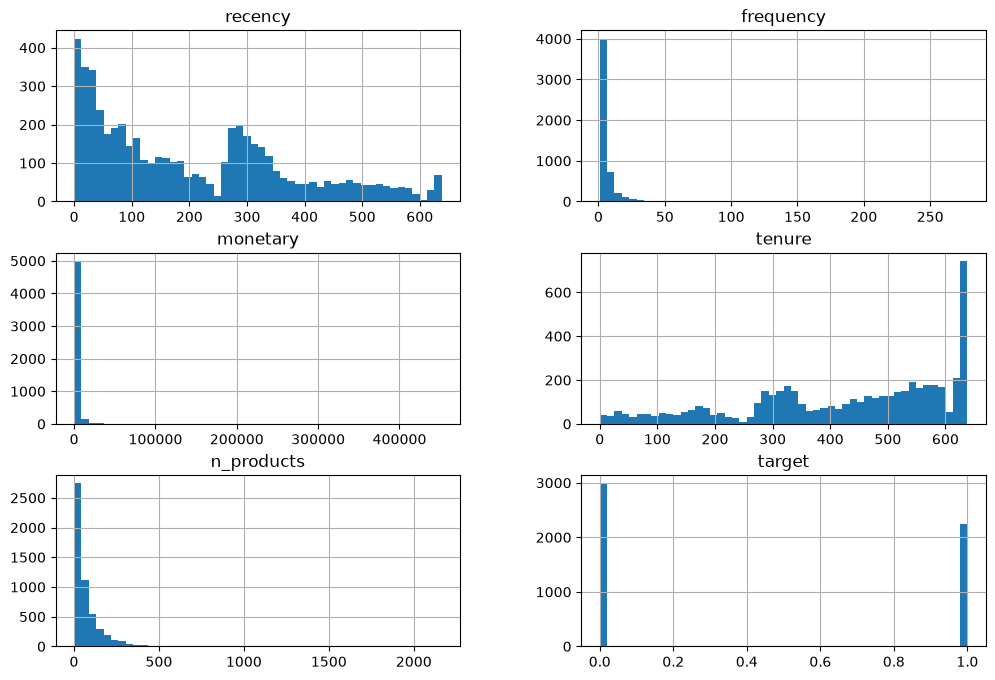

In [18]:
customers.hist(bins=50, figsize=(12,8))

<Axes: >

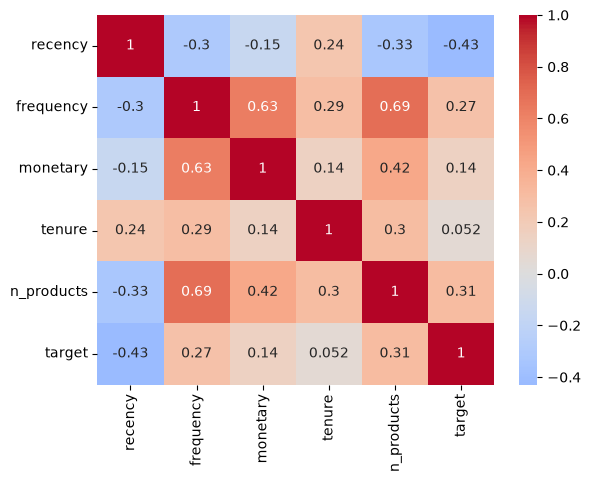

In [21]:
sns.heatmap(customers.corr(), annot=True, cmap="coolwarm", center=0)


<Axes: >

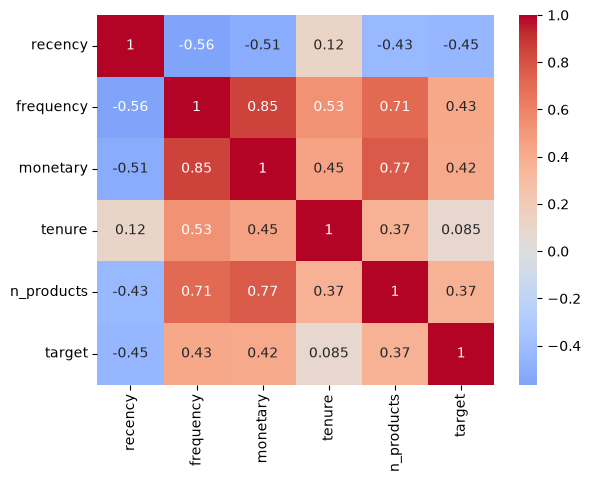

In [26]:
sns.heatmap(customers.corr(method="spearman"), annot=True, cmap="coolwarm", center=0)


In [ ]:
customers.groupby("target").median()


,recency,frequency,monetary,tenure,n_products
target,,,,,
0,276.0,2.0,476.105,449.0,28.0
1,69.0,5.0,1599.670,494.0,71.0


<Axes: xlabel='target', ylabel='recency'>

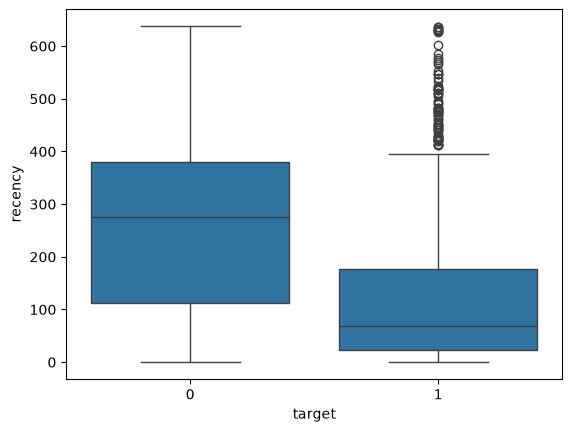

In [23]:
sns.boxplot(data=customers, x="target", y="recency")

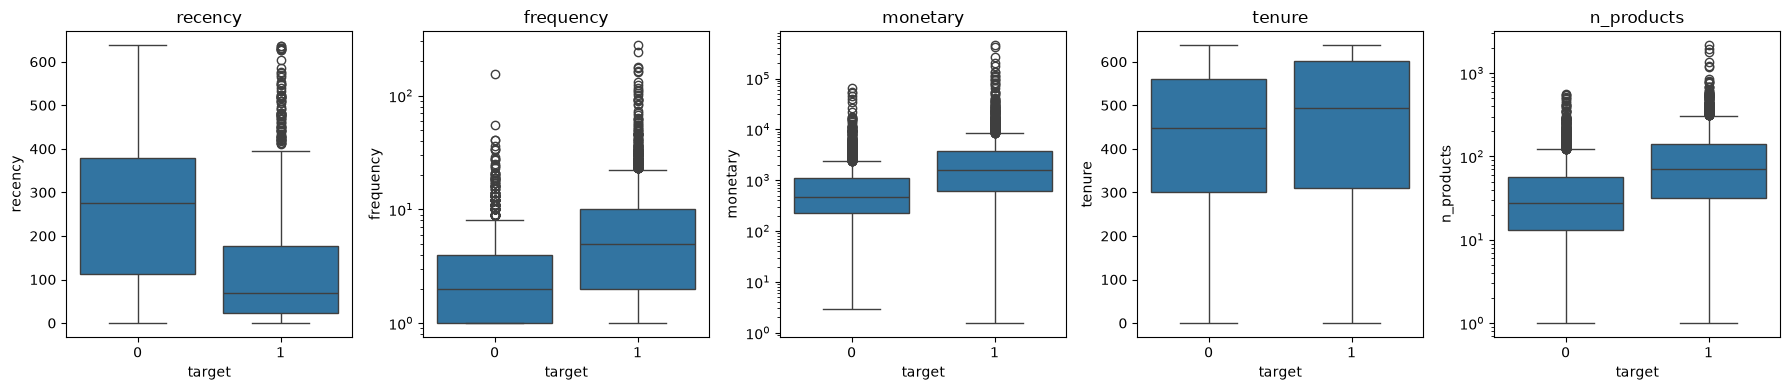

In [30]:
features = ["recency", "frequency", "monetary", "tenure", "n_products"]
skewed = ["frequency", "monetary", "n_products"]

fig, axes = plt.subplots(1, len(features), figsize=(18, 4))

for ax, col in zip(axes, features):
    sns.boxplot(data=customers, x="target", y=col, ax=ax)
    if col in skewed:
        ax.set_yscale("log")
    ax.set_title(col)
plt.tight_layout()

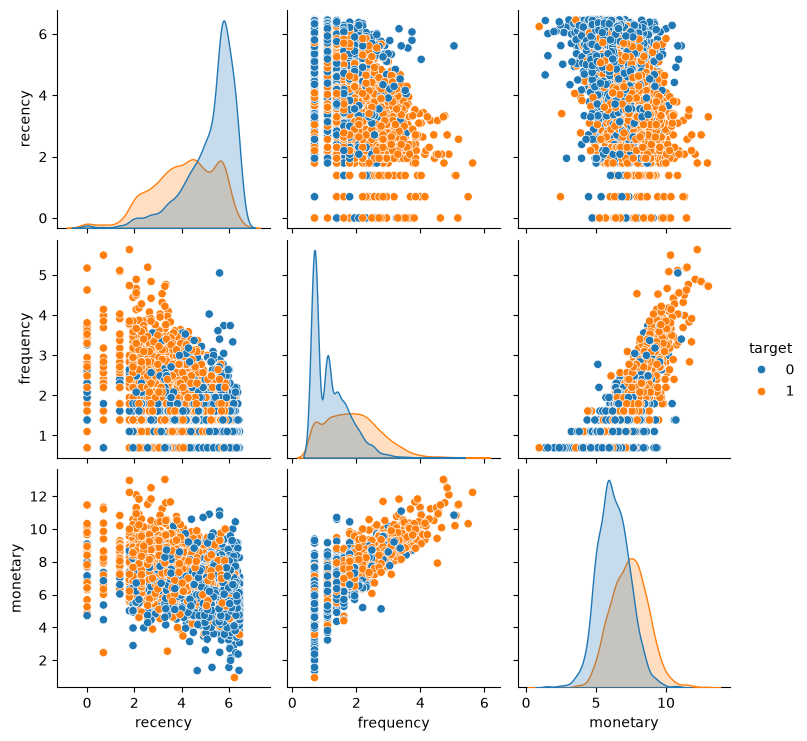

In [25]:
sns.pairplot(np.log1p(customers[["recency", "frequency", "monetary"]]).join(customers["target"]), hue="target")


target balance: 57 % did not return, 43 % returned

histogram: 
frequency, monetary, n_products: long tailed- log transform them for linear models
recendcy: many cutomers shopped recently, and last christmas 
tenure: showing that some customers have longer tenure than dataset, somewhat unreliable feature for oldest customers.

heatmap:
recency: .0.43 - recent buy gives better chance of buying again
n_products: 0.31 - buying diff products corr to rebuy
monetary: 0.14, weak, stronger in spearman, better to log transform
frequency 0.27 in pearson, 0.42 in spearman, also log transform
tenure: almost not corr
frequency, monetary and frecuency n_products connected- active customers buy more- high corr. maybe random forest can deal better with that

box-plot: seems like some customers return only for christmas, new feature "bought_last_q4"
recency, frequency monetary and n_products seem to have good separation of target. tenure does not(alone).